# Exploratory data analysis

        This notebook uses the development outputs from `python scripts/run_eda.py`.
        Run that command from the project root before starting a fresh kernel.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src import config

## Data source and scope

The project uses the [Air Quality - Mediterranean Basin dataset](https://www.kaggle.com/datasets/sarahameziane/air-quality-mediterranean-basin-20162026).
The combined Kaggle release's license was not verified. The prepared data contain daily
station observations of surface PM2.5, satellite retrievals, and meteorological predictors.
The date range below comes from the cleaned development parquet.

In [2]:
keys = pd.read_parquet(config.PROCESSED / "clean_dev.parquet", columns=["date", "station_id"])
assert keys["date"].lt(pd.Timestamp(config.TEST_START)).all()
display(pd.Series({
    "First development date": keys["date"].min().date(),
    "Last development date": keys["date"].max().date(),
    "Station-days": len(keys),
    "Stations": keys["station_id"].nunique(),
}, name="Development cohort").to_frame())

,Development cohort
First development date,2016-11-25
Last development date,2024-12-31
Station-days,31282
Stations,70


## Variables and descriptive statistics

Units below are recorded in `results/parts/audit.csv`, which attributes them to the
Kaggle dataset description. Station and GEE identifiers are categorical metadata. Dates,
timestamps, and station coordinates identify observation rows.

| Measurements | Units recorded in the audit |
| --- | --- |
| Surface PM2.5 | µg/m³ |
| MODIS aerosol optical depth (AOD) | Dimensionless |
| Sentinel-5P NO₂, CO, O₃ columns | mol/m² |
| Temperature | °C |
| Pressure | hPa |
| Wind components and derived wind speed | m/s |

The descriptive table summarizes observed values in the cleaned development data.

In [3]:
eda = pd.read_csv(config.RESULTS / "Exploratory_Data.csv")
metrics = ["n", "min", "mean", "median", "max", "sd"]
stats = eda.loc[
    eda["section"].eq("5.1") & eda["group"].eq("all") & eda["metric"].isin(metrics)
].copy()
stats["value"] = pd.to_numeric(stats["value"])
display(stats.pivot(index="variable", columns="metric", values="value")[metrics].round(5))

metric,n,min,mean,median,max,sd
variable,,,,,,
aod,31282.0,0.00000,0.15166,0.13100,5.47500,0.10621
co,28875.0,0.01306,0.03168,0.03157,0.06084,0.00375
no2,28875.0,0.00003,0.00009,0.00009,0.00048,0.00003
o3,28834.0,0.10390,0.14237,0.13947,0.22932,0.01409
pm25,31282.0,0.00667,9.31629,7.73317,484.98150,10.34496
pressure_mb,31282.0,933.02257,993.51675,997.89240,1033.66218,17.67044
temperature_celsius,31282.0,-0.56920,18.48459,18.92442,34.86583,6.19418
wind_speed,31282.0,0.01035,2.34922,1.69799,13.26139,1.82902
wind_u,31282.0,-11.09872,0.30627,0.16376,8.83419,2.62483


## Missingness by variable and by station

This table counts missing values as recorded in the cleaned data. AOD zeros are
handled separately as failed retrievals during model preprocessing. The station table
shows the ten stations with the highest recorded Sentinel-5P missingness. The heatmap
gives the broader station comparison.

metric,missing_n,missing_pct
variable,,
aod,0.0,0.00
co,2407.0,7.69
no2,2407.0,7.69
o3,2448.0,7.83
pm25,0.0,0.00
pressure_mb,0.0,0.00
temperature_celsius,0.0,0.00
wind_u,0.0,0.00
wind_v,0.0,0.00


variable,co,no2,o3
station,,,
FR03030,55.48,55.48,56.18
FR03006,47.31,47.31,47.69
FR03043,46.47,46.47,47.21
FR03029,45.85,45.85,46.64
VALÈNCIA - MOLÍ DEL SOL,30.72,30.72,30.72
QUART DE POBLET,21.48,21.48,21.90
VALÈNCIA-PISTA DE SILLA,21.48,21.48,21.90
ALMASSORA-C. P. OCHANDO,21.11,21.11,21.38
VALÈNCIA-POLITÈCNIC,20.94,20.94,21.35


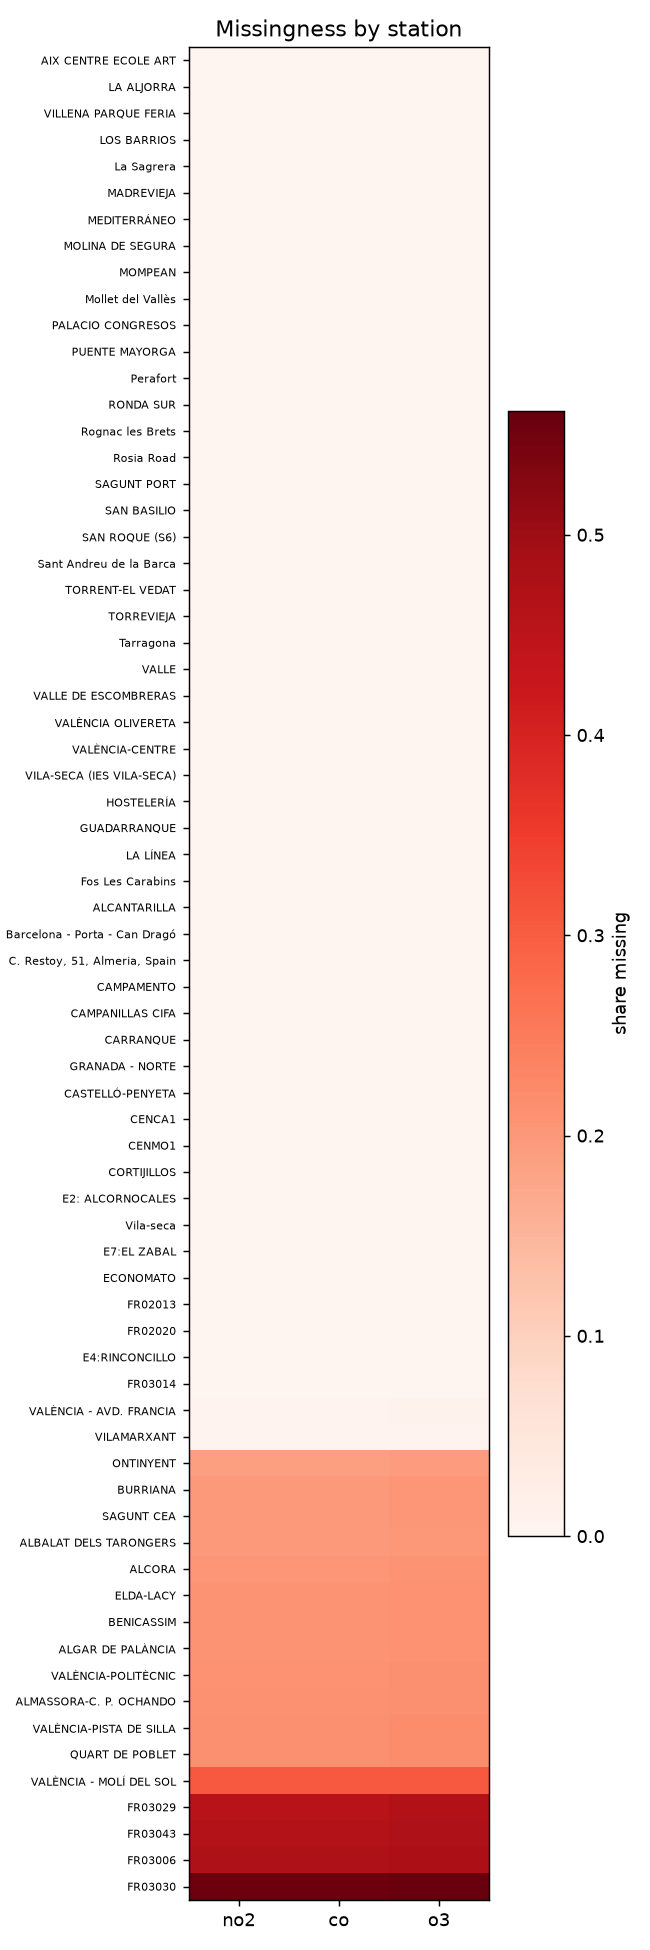

In [4]:
missing = eda.loc[eda["metric"].isin(["missing_n", "missing_share"])].copy()
missing["value"] = pd.to_numeric(missing["value"])
overall = missing.loc[missing["group"].eq("all")].pivot(
    index="variable", columns="metric", values="value"
)
display(overall.assign(missing_pct=overall.pop("missing_share").mul(100)).round(2))

stations = missing.loc[
    missing["group"].str.startswith("station=", na=False)
    & missing["metric"].eq("missing_share")
].copy()
stations["group"] = stations["group"].str.removeprefix("station=")
station_pct = stations.pivot(index="group", columns="variable", values="value").mul(100)
worst = station_pct.max(axis=1).nlargest(10).index
display(station_pct.loc[worst].round(2).rename_axis("station"))
display(Image(filename=str(config.FIGURES / "m2_missing_by_station.png"), width=820))

## Cleaning decisions

Missing, nonpositive, and implausibly high PM2.5 values were removed first. The cleaner
kept the first exact duplicate and the first record with identical station, coordinates,
and date. If station and date still conflicted after that check, it removed every record
in that conflict. Extreme PM2.5 within the valid interval was retained. The counts below
are in cleaning order.

In [5]:
cleaning = pd.read_csv(config.PARTS / "cleaning_log.csv", keep_default_na=False)
display(cleaning[["rule", "rows_before", "rows_removed", "rows_after", "note"]])

,rule,rows_before,rows_removed,rows_after,note
0,combined_gee_pm25.csv; dated rows before 2025-...,31998,0,31998,
1,pm25 is missing,31998,0,31998,(0 were non-numeric text)
2,pm25 <= 0,31998,704,31294,
3,pm25 >= 500,31294,8,31286,
4,"identical in all columns, keep first",31286,0,31286,
5,date+lat+lon+station_id; rule=first,31286,0,31286,
6,station_id+date; rule=drop_all,31286,4,31282,"(2 groups, saved in sensor_day_duplicates.csv)"


## Distributions and relationships

The histograms show the contrast between the strongly right-skewed PM2.5 distribution and
the meteorological and satellite measurements. The Pearson matrix uses pairwise complete
development observations and treats zero AOD as missing, as the relationship script does.
It summarizes observed associations.

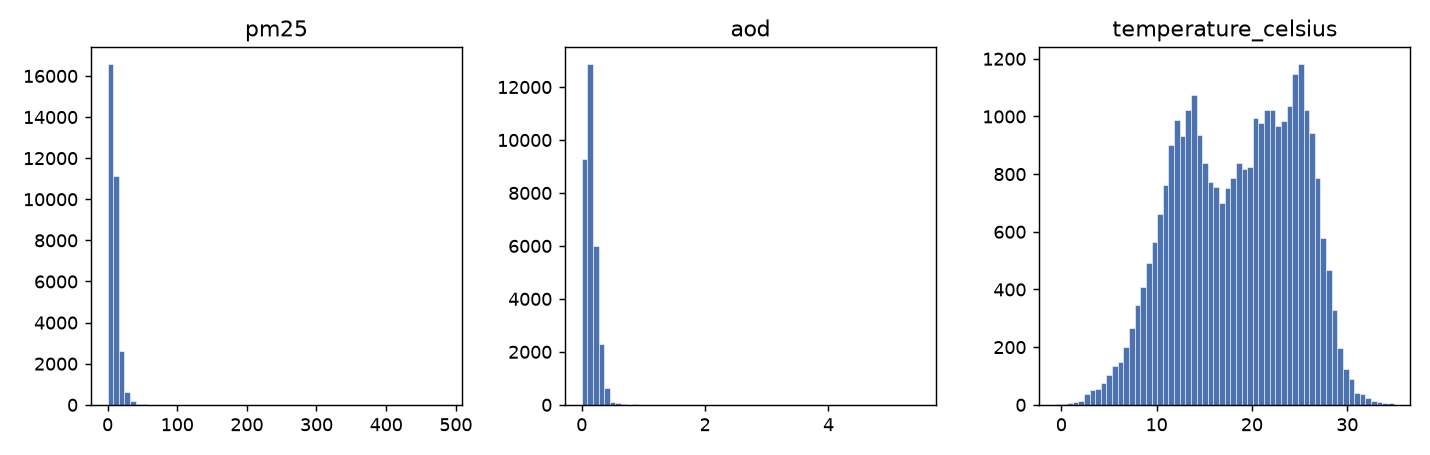

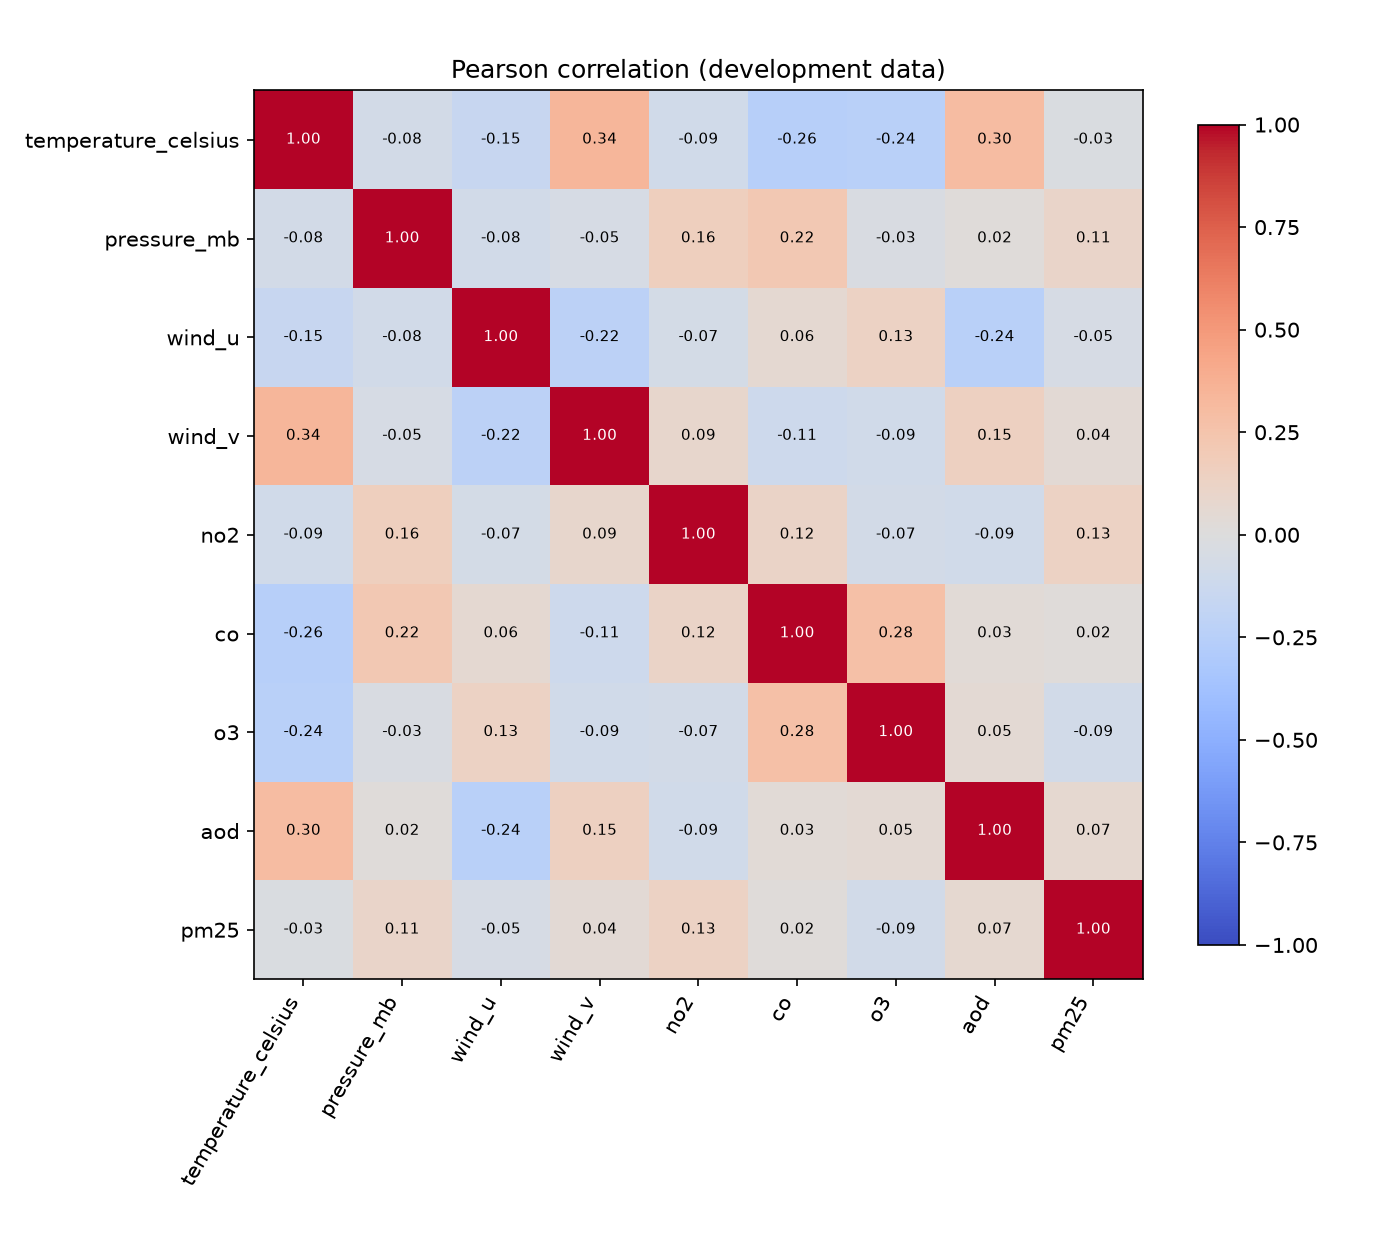

In [6]:
display(
    Image(filename=str(config.FIGURES / "eda_histogrammes.png"), width=850),
    Image(filename=str(config.FIGURES / "correlation_matrix.png"), width=650),
)

## Implications for preprocessing

Fit clipping, imputation, and any model-dependent scaling on each training fold. Treat
zero AOD as missing. Use training medians and keep Sentinel-5P missingness indicators.
The first temporal training fold has no observed Sentinel-5P values, so the imputer
uses its documented zero placeholder for missing entries in that fold. Keep the retained
PM2.5 extremes in evaluation and keep station identifiers and coordinates out of the
model predictors. See `results/phase1_methodology.md` for the recorded decisions.